In [9]:
import etunc.config as ec
import etunc.grid as eg
import etunc.load.obs as lo
import etunc.binning as eb
import etunc.load.era5 as le

from etunc.units import accumulation_to_flux, latent_heat_to_wm2, convert_units
from etunc.temporal import annual_mean

In [30]:
da = le.load_era5("mer", "2001-01", "2001-12")
da = eg.format_grid(da)
da = convert_units("mer", da)
mask = eg.land_mask(da)

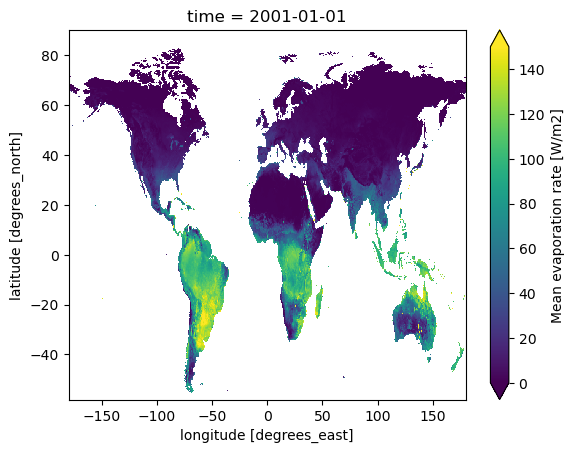

In [31]:
da.isel(time=0).where(mask).sel(lat=slice(-58, 90)).plot(vmin=0, vmax=150)

In [2]:
TSLICE = slice("1995-01", "2014-12")

In [3]:
gleam_m = lo.load_obs("gleam", "E", time_slice=TSLICE, version="v4.3a", freq="monthly").sel(lat=ec.LAT_BNDS)
pml_m = lo.load_obs("pml", "E", time_slice=TSLICE, version="V2.2b", freq="monthly").sel(lat=ec.LAT_BNDS)
sith_m = lo.load_obs("sith", "ET", time_slice=TSLICE, version="v2", freq="monthly").sel(lat=ec.LAT_BNDS)

In [11]:
gleam_y = annual_mean(latent_heat_to_wm2(accumulation_to_flux(gleam_m)), require_all_months=True)
pml_y = annual_mean(latent_heat_to_wm2(accumulation_to_flux(pml_m)), require_all_months=True)
sith_y = annual_mean(latent_heat_to_wm2(accumulation_to_flux(sith_m)), require_all_months=True)

assert eg.equal_coords(gleam_y, pml_y, ("lat", "lon"))
assert eg.equal_coords(gleam_y, sith_y, ("lat", "lon"))

mask = eg.land_mask(gleam_y)

valid = gleam_y.notnull().all("year") & pml_y.notnull().all("year") & sith_y.notnull().all("year")

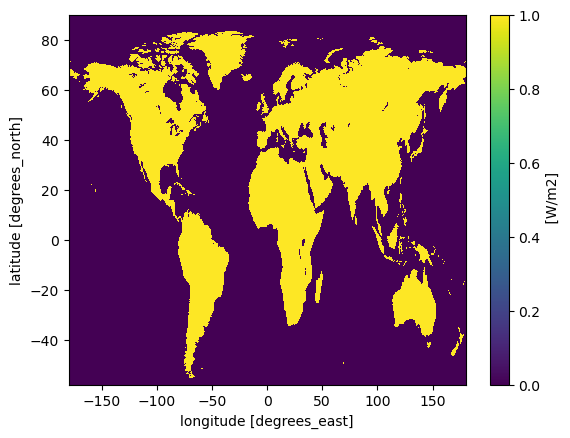

: 

In [ ]:
valid.plot()

In [16]:
gleam_rg = lo.load_obs_regridded("gleam", "E", res=1, time_slice=slice("2005-01", "2006-12"), version="v4.3a")
pml_rg = lo.load_obs_regridded("pml", "E", res=1, time_slice=slice("2005-01", "2006-12"), version="V2.2a-MODIS")
sith_rg = lo.load_obs_regridded("sith", "ET", res=1, time_slice=slice("2005-01", "2006-12"), version="v2")

gleam v4.3a monthly E: regridded 2 files to 1 deg (load 10.5s, regrid 94.1s)
pml V2.2a-MODIS monthly E: regridded 2 files to 1 deg (load 1.1s, regrid 68.5s)
sith v2 monthly ET: regridded 1 files to 1 deg (load 3.3s, regrid 1.1s)


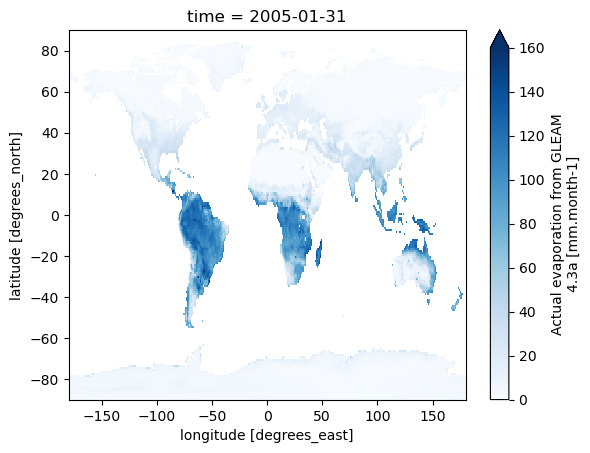

In [21]:
gleam_rg.isel(time=0).plot(vmin=0, vmax=160, extend="max", cmap="Blues")

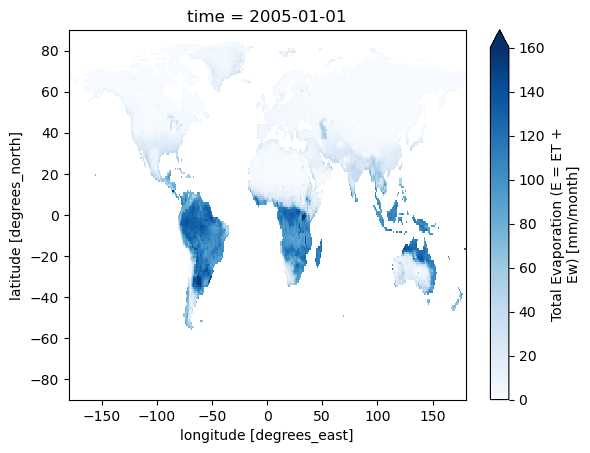

In [23]:
pml_rg.isel(time=0).plot(vmin=0, vmax=160, extend="max", cmap="Blues")

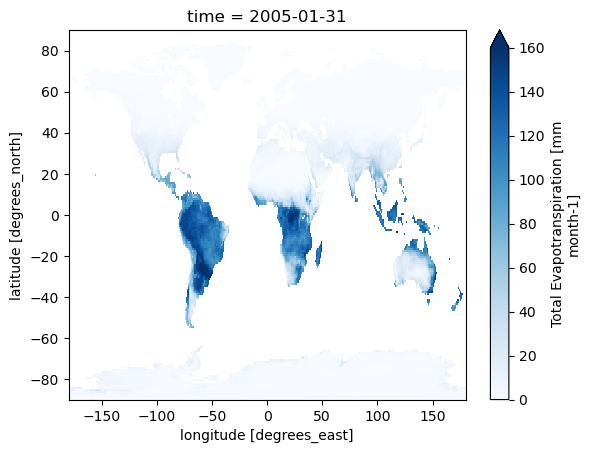

In [24]:
sith_rg.isel(time=0).plot(vmin=0, vmax=160, extend="max", cmap="Blues")